# Семинар 10. Сжатие моделей

Обучаем компактный трансформер воспроизводить эмбеддинги учителя, выполняем постслойный прунинг и сравниваем качество классификации до и после обнуления весов. Затем загружаем языковую модель с 4-битной квантизацией и получаем ответ на запрос.

В Google Colab выберите среду с GPU и выполняйте ячейки по порядку. Первый запуск загружает модели и AG News из сети. Ответы на вопросы находятся в свернутых разделах.

In [1]:
%pip install -q "torch>=2.6,<3" "transformers==5.20.2" "datasets==4.8.5" "huggingface-hub==1.33.0" "accelerate==1.15.0" "bitsandbytes==0.50.2" "numpy>=2,<3" "matplotlib>=3.8,<4" "seaborn==0.13.2" "tqdm>=4.66,<5" "ipywidgets>=8.1,<9"

In [2]:
import math
import os
import gc
import random

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import (
    AutoModel,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)

os.environ["TOKENIZERS_PARALLELISM"] = "false"
sns.set(style="whitegrid")

### Настройка устройства и случайных состояний

Выбираем CUDA, MPS или CPU и фиксируем seed для Python, NumPy и PyTorch.

In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)
compute_dtype = (
    torch.bfloat16 if device.type == "mps" or (
        device.type == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
    ) else torch.float16 if device.type == "cuda" else torch.float32
)
print("Устройство:", device, "тип вычислений учителя:", compute_dtype)

Устройство: cuda тип вычислений учителя: torch.float16


## Дистилляция эмбеддингов

#### **Вопрос**. Как вы думаете, что еще можно учесть из модели Teacher? Допустим, Teacher и Student имеют одну архитектуру, но разное число слоев.

#### Ответ

Можно связать промежуточные слои. Такой подход предложен в [FitNets](https://arxiv.org/abs/1412.6550).

### Загрузка модели-учителя

Загружаем `Qwen/Qwen3-Embedding-0.6B` и ее токенизатор. Учитель работает в режиме `eval`, все его параметры заморожены. Студент обучается воспроизводить нормализованное среднее скрытых состояний учителя по токенам.

Здесь сохранен mean-pooling исходного эксперимента. Штатная схема Qwen3-Embedding использует представление последнего токена; результаты этого блока относятся к mean-pooling.

In [4]:
teacher_name = "Qwen/Qwen3-Embedding-0.6B"
teacher_tokenizer = AutoTokenizer.from_pretrained(
    teacher_name,
    padding_side="left",
    revision="97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
)
if teacher_tokenizer.pad_token_id is None:
    teacher_tokenizer.pad_token = teacher_tokenizer.eos_token

teacher_model = AutoModel.from_pretrained(
    teacher_name, dtype=compute_dtype,
    revision="97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
)
teacher_model.eval().to(device)
for p in teacher_model.parameters():
    p.requires_grad = False

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.71k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

#### **Функции пулинга и нормализации эмбеддингов**

- `mean_pooling`: вычисляет среднее по токенам с учетом маски внимания (игнорирует padding).  
- `l2_normalize`: нормализует векторы эмбеддингов по L2-норме для стабильности и совместимости с метриками вроде косинусного сходства.

In [5]:
def mean_pooling(last_hidden_state, attention_mask):
    # last_hidden_state: [B, T, H], mask: [B, T]
    mask = attention_mask.unsqueeze(-1).float()  # [B, T, 1]
    summed = (last_hidden_state * mask).sum(dim=1)  # [B, H]
    counts = mask.sum(dim=1).clamp(min=1e-6)  # [B, 1]
    return summed / counts


def l2_normalize(x, eps=1e-8):
    return x / (x.norm(dim=-1, keepdim=True) + eps)

### **Архитектура и инициализация модели-студента (~100M параметров)**

Реализован компактный трансформер-энкодер (`StudentEncoder`) с 8 слоями, скрытой размерностью 512 и выходной проекцией в 1024-мерное пространство. Используется позиционное кодирование, предварительная нормализация (pre-norm), mean-pooling по токенам и L2-нормализация выходных эмбеддингов. Модель инициализируется с тем же словарем и `pad_token_id`, что и учитель. Общее число параметров - ~100 млн, все обучаемые.

In [6]:
class StudentEncoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        d_model: int          = 512,
        n_heads: int          = 8,
        n_layers: int         = 8,
        dim_ff: int           = 2048,
        max_len: int          = 2048,
        out_dim: int          = 1024,
        dropout: float        = 0.1,
        pad_token_id: int     = 0,
    ):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.pos_emb   = nn.Embedding(max_len,  d_model)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,      # -> [B,T,d] во всем коде
            activation="gelu",     # то же, что в оригинале
            norm_first=True        # pre-norm
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.norm   = nn.LayerNorm(d_model)
        self.proj   = nn.Linear(d_model, out_dim)
        self.dropout = nn.Dropout(dropout)

        self.max_len = max_len
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.normal_(self.token_emb.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.pos_emb.weight,   mean=0.0, std=0.02)
        nn.init.xavier_uniform_(self.proj.weight)
        if self.proj.bias is not None:
            nn.init.zeros_(self.proj.bias)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor):
        """
        input_ids:     [B, T]
        attention_mask [B, T] (1 - токен, 0 - паддинг)
        """
        B, T = input_ids.shape
        if T > self.max_len:
            raise ValueError(f"Sequence length {T} > max_len {self.max_len}")

        # --- embeddings ---
        pos_ids = torch.arange(T, device=input_ids.device).unsqueeze(0).expand(B, T)
        x = self.token_emb(input_ids) + self.pos_emb(pos_ids)  # [B,T,d]

        # --- encoder ---
        x = self.encoder(
            x,
            src_key_padding_mask=(attention_mask == 0)  # True там, где паддинг
        )                                               # [B,T,d]

        # --- pooling, проекция, L2 ---
        x = self.norm(x)
        pooled = mean_pooling(x, attention_mask)        # [B,d]
        pooled = self.dropout(pooled)
        out = self.proj(pooled)                         # [B,out_dim]
        return l2_normalize(out)                        # [B,out_dim]


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# Инициализация студента
vocab_size = len(teacher_tokenizer)
student_model = StudentEncoder(
    vocab_size=vocab_size,
    d_model=512,
    n_heads=8,
    n_layers=8,
    dim_ff=2048,
    max_len=2048,
    out_dim=teacher_model.config.hidden_size,
    pad_token_id=teacher_tokenizer.pad_token_id
).to(device)

total_params, trainable_params = count_params(student_model)
print(
    f"Student params: total={total_params / 1e6:.1f}M, trainable={trainable_params / 1e6:.1f}M"
)

/tmp/ipykernel_1602/1488264388.py:28: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)


Student params: total=104.4M, trainable=104.4M


### Подготовка данных

Используем AG News: 20 000 обучающих текстов и 2 000 текстов из тестовой части для оценки сходства с учителем. Разметка классов при дистилляции не используется. Тексты токенизируются токенизатором учителя, длина ограничена 128 токенами, размер батча - 64.

Число эпох и параметры обучения заданы заранее. Тестовая часть используется только для итогового сравнения.

In [7]:
raw_ds = load_dataset(
    "sh0416/ag_news", revision="70e3fa1915be9a8daebec5e840f20df9a8e18793"
)
# В этой версии AG News заголовок и описание хранятся раздельно.
if "text" not in raw_ds["train"].column_names:
    raw_ds = raw_ds.map(lambda item: {"text": item["title"] + " " + item["description"]})

README.md:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 33.7MB            

train.jsonl: downloading bytes:           |  0.00B            

test.jsonl:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [8]:
# Для быстрого примера уменьшим выборку
train_samples = 20000
val_samples = 2000
max_length = 128
batch_size = 64

train_texts = raw_ds["train"]["text"][:train_samples]
val_texts = raw_ds["test"]["text"][:val_samples]


def collate_fn(batch_texts):
    enc = teacher_tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )
    return {k: v for k, v in enc.items()}


train_loader = DataLoader(
    train_texts,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
)
val_loader = DataLoader(
    val_texts,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)

### Получение эмбеддингов и оценка сходства

`teacher_embed` и `student_embed` возвращают L2-нормализованные эмбеддинги без вычисления градиентов. `evaluate_avg_cosine` усредняет косинусное сходство студента с учителем на отложенных текстах. Проекция студента задает ту же размерность выхода, что и у учителя.

In [9]:
@torch.no_grad()
def teacher_embed(input_ids, attention_mask):
    outputs = teacher_model(input_ids=input_ids, attention_mask=attention_mask)
    # Ожидаем last_hidden_state
    last_hidden_state = outputs.last_hidden_state  # [B, T, H_t]
    pooled = mean_pooling(last_hidden_state, attention_mask)
    emb = l2_normalize(pooled)
    return emb  # [B, H_t]


@torch.no_grad()
def student_embed(input_ids, attention_mask):
    return student_model(input_ids=input_ids, attention_mask=attention_mask)


@torch.no_grad()
def evaluate_avg_cosine(student_model, data_loader, limit_batches=None):
    student_model.eval()
    teacher_model.eval()
    total_cos = 0.0
    total_n = 0
    print("evaluate_avg_cosine")
    for i, batch in tqdm(enumerate(data_loader), total=len(data_loader)):
        if limit_batches is not None and i >= limit_batches:
            break
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        t_emb = teacher_embed(input_ids, attention_mask)
        s_emb = student_embed(input_ids, attention_mask)

        assert t_emb.shape == s_emb.shape, (t_emb.shape, s_emb.shape)

        cos = F.cosine_similarity(s_emb, t_emb, dim=-1)  # [B]
        total_cos += cos.sum().item()
        total_n += cos.numel()

    return total_cos / max(total_n, 1)

### **Настройка процесса дистилляции**  

Инициализируем оптимизатор (`AdamW`), линейный LR-планировщик с прогревом (`warmup`) и `GradScaler` для обучения со смешанной точностью (AMP) на CUDA. В качестве функции потерь используется **MSE** между эмбеддингами студента и учителя. Обучение запланировано на 1 эпоху с начальной скоростью обучения `5e-4`.

In [10]:
lr = 5e-4
epochs = 1
warmup_ratio = 0.05
use_amp = torch.cuda.is_available()

optimizer = torch.optim.AdamW(
    student_model.parameters(), lr=lr, weight_decay=0.01
)

num_train_steps = epochs * math.ceil(len(train_loader))
num_warmup_steps = int(warmup_ratio * num_train_steps)
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps, num_train_steps
)

scaler = torch.amp.GradScaler(enabled=use_amp)
mse_loss = nn.MSELoss()

#### Оценка начального сходства

Вычисляем среднее косинусное сходство с учителем до обучения студента. После обучения повторяем оценку на тех же текстах.

In [11]:
pre_cos = evaluate_avg_cosine(
    student_model, val_loader
)
print(f"Avg cosine to teacher BEFORE: {pre_cos:.4f}")

evaluate_avg_cosine


  0%|          | 0/32 [00:00<?, ?it/s]

Avg cosine to teacher BEFORE: -0.0216


### **Процесс дистилляции эмбеддингов**  

Модель-студент обучается минимизировать **MSE-потерю** между своими L2-нормализованными эмбеддингами и эмбеддингами учителя.  
- Эмбеддинги учителя вычисляются один раз за шаг без градиентов.  
- На CUDA используется **обучение со смешанной точностью (AMP)** для ускорения и экономии памяти.  
- Градиенты обрезаются (`clip_grad_norm_=1.0`) для стабильности.  
- Обучение идет с прогревом и линейным затуханием learning rate.  
- Потери выводятся каждые 100 шагов для мониторинга сходимости.

In [12]:
student_model.train()
for epoch in range(epochs):
    running_loss = 0.0
    for step, batch in tqdm(enumerate(train_loader), total=len(train_loader)):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        with torch.no_grad():
            t_emb = teacher_embed(input_ids, attention_mask)  # [B, H_t]

        with torch.amp.autocast(device_type="cuda", enabled=use_amp):
            s_emb = student_model(
                input_ids=input_ids, attention_mask=attention_mask
            )  # [B, 1024] (нормализованный)
            t_emb = l2_normalize(t_emb)
            assert t_emb.shape == s_emb.shape, (t_emb.shape, s_emb.shape)

            loss = mse_loss(s_emb, t_emb)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(student_model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item()
        if (step + 1) % 100 == 0:
            avg_loss = running_loss / 100
            print(
                f"Epoch {epoch + 1} | step {step + 1}/{len(train_loader)} | loss={avg_loss:.4f}"
            )
            running_loss = 0.0

  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 1 | step 100/313 | loss=0.0006
Epoch 1 | step 200/313 | loss=0.0005
Epoch 1 | step 300/313 | loss=0.0005


#### **Оценка улучшения после дистилляции**

Вычисляется среднее косинусное сходство между эмбеддингами студента и учителя **после обучения** на той же подвыборке валидационных данных. Сравнение с метрикой «до обучения» показывает, насколько успешно прошла дистилляция: рост значения косинуса указывает на приближение эмбеддингов студента к эмбеддингам учителя.

In [13]:
post_cos = evaluate_avg_cosine(student_model, val_loader)
print(f"\n\nAvg cosine to teacher AFTER:  {post_cos:.4f}")

evaluate_avg_cosine


  0%|          | 0/32 [00:00<?, ?it/s]



Avg cosine to teacher AFTER:  0.7379


## Прунинг

### Подготовка данных для прунинга

Используем 1000 обучающих и 128 тестовых примеров AG News с метками классов. Для каждого класса вычисляем центроид обучающих эмбеддингов и классифицируем тестовые тексты по косинусному сходству с центроидами. Затем обнуляем часть весов учителя и повторяем оценку на тех же данных.

In [14]:
train_samples = 1000
val_samples = 128
max_length = 128
batch_size = 64

train_texts = raw_ds["train"]["text"][:train_samples]
val_texts = np.array(raw_ds["test"]["text"][:val_samples])

train_labels = np.array(raw_ds["train"]["label"][:train_samples])
val_labels = np.array(raw_ds["test"]["label"][:val_samples])


def collate_fn(batch_texts):
    enc = teacher_tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )
    return {k: v for k, v in enc.items()}


train_loader = DataLoader(
    train_texts,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)
val_loader = DataLoader(
    val_texts,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)

### Оценка качества после прунинга

- `get_embeddings` извлекает векторы текстов без градиентов. Для Qwen используется mean-pooling по последнему скрытому слою.
- `normalize_rows` нормализует строки матрицы эмбеддингов.
- `prototypical_accuracy` вычисляет центроиды классов по обучающим данным и точность классификации тестовых текстов.
- `cosine_self_similarity` сравнивает представления одних и тех же текстов до и после прунинга.

In [15]:
@torch.no_grad()
def get_embeddings(model, loader, device):
    embs = []
    for batch in tqdm(loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        out = model(**batch)
        # Универсальный пуллинг: pooler_output, если есть, иначе mean pooling
        if hasattr(out, "pooler_output") and out.pooler_output is not None:
            pooled = out.pooler_output
        else:
            last = (
                out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
            )
            mask = batch.get(
                "attention_mask", torch.ones(last.shape[:2], device=last.device)
            )
            mask = mask.unsqueeze(-1).type_as(last)
            pooled = (last * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-6)
        embs.append(pooled.detach().cpu())

    embs_tensor = torch.cat(embs, dim=0)
    return embs_tensor.float().numpy()


def normalize_rows(x, eps=1e-9):
    n = np.linalg.norm(x, axis=1, keepdims=True) + eps
    return x / n


def prototypical_accuracy(X_train, y_train, X_val, y_val):
    """Косинусная близость к центроидам классов"""
    Xtr = normalize_rows(X_train)
    Xva = normalize_rows(X_val)
    classes = np.unique(y_train)
    centroids = np.vstack([Xtr[y_train == c].mean(axis=0) for c in classes])
    centroids = normalize_rows(centroids)
    sims = Xva @ centroids.T  # косинусы
    preds = classes[np.argmax(sims, axis=1)]
    acc = float((preds == y_val).mean())
    return acc, preds


def cosine_self_similarity(A, B, k=None):
    """Косинусная близость эмбеддингов "до" и "после" для одних и тех же текстов"""
    assert A.shape == B.shape
    if k is not None and k < A.shape[0]:
        idx = np.random.choice(A.shape[0], size=k, replace=False)
        A = A[idx]
        B = B[idx]
    A = normalize_rows(A)
    B = normalize_rows(B)
    return np.sum(A * B, axis=1)

#### **Базовое качество до прунинга**  

Вычисляются эмбеддинги обучающей и валидационной выборок с помощью исходной модели-учителя. На их основе оценивается точность классификации методом **ближайшего центроида** (с косинусным сходством). Это значение служит **бейзлайном** для сравнения с результатами после прунинга.

In [16]:
print("Вычисляем эмбеддинги (до прунинга)...")
Xtr_before = get_embeddings(teacher_model, train_loader, device)
Xva_before = get_embeddings(teacher_model, val_loader, device)
acc_before, _ = prototypical_accuracy(Xtr_before, train_labels, Xva_before, val_labels)
print(f"Accuracy до прунинга (Nearest Centroid, cosine): {acc_before:.4f}")

Вычисляем эмбеддинги (до прунинга)...


  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Accuracy до прунинга (Nearest Centroid, cosine): 0.8594


#### **Анализ весов модели перед прунингом**  

- `get_linear_modules`: собирает все линейные (`nn.Linear`) слои модели с их именами.  
- `sample_weight_magnitudes`: для каждого линейного слоя оценивает:  
  - **абсолютные значения весов** (сэмплирует до `samples_per_layer` элементов),  
  - **разреженность** - долю нулевых весов.  

Эти данные (`mags_before`, `zeros_before`) дают представление о текущем распределении весов и уровне разреженности **до прунинга**, что полезно для выбора стратегии и порога удаления.

In [17]:
def get_linear_modules(model: nn.Module):
    mods = []
    for name, m in model.named_modules():
        if isinstance(m, nn.Linear):
            mods.append((name, m))
    return mods


def sample_weight_magnitudes(linear_modules, samples_per_layer=50000):
    """Возвращает сэмплы |w| и разреженность по слоям"""
    mags = []
    zeros = {}
    for name, m in linear_modules:
        w = m.weight.detach().float().cpu().flatten()
        zeros[name] = float((w == 0).sum().item()) / w.numel()
        n = min(samples_per_layer, w.numel())
        if n > 0:
            idx = torch.randint(low=0, high=w.numel(), size=(n,))
            mags.append(w[idx])
    mags = torch.cat(mags).abs().numpy() if mags else np.array([])
    return mags, zeros


linears = get_linear_modules(teacher_model)
mags_before, zeros_before = sample_weight_magnitudes(linears, samples_per_layer=1000)

### Постслойный прунинг по модулю весов

`prune_layerwise_inplace` обнуляет примерно 30% наименьших по модулю весов отдельно в каждом выбранном линейном слое. При совпадении значений на пороге доля нулей может быть немного больше. `should_skip_layer` исключает проекции запросов и ключей; нормализации и эмбеддинги также не затрагиваются.

Порог определяется на CPU, маска применяется частями на устройстве. Функция возвращает разреженность слоев и фрагменты масок. Размеры плотных матриц при обнулении не меняются.

In [18]:
def should_skip_layer(name):
    # Не трогаем q/k, нормировки и эмбеддинги
    bad = ["q_proj", "k_proj", "norm", "ln", "embed", "embeddings", "position"]
    return any(b in name.lower() for b in bad)


@torch.no_grad()
def prune_layerwise_inplace(
    linear_modules, amount=0.3, chunk=2_000_000, collect_patches=3
):
    """
    amount: доля весов на слой (0..1)
    chunk: размер чанка при применении маски (элементов), чтоб не съедать VRAM
    collect_patches: сколько патчей масок сохранить для визуализации
    """
    stats = {}
    mask_patches = {}
    patches_left = collect_patches

    for name, m in linear_modules:
        if should_skip_layer(name):
            continue
        W = m.weight
        n = W.numel()
        if n == 0 or amount <= 0:
            continue

        # 1) Порог по квантилю на CPU (дешево по VRAM)
        abs_cpu = W.detach().float().abs().view(-1).cpu()
        k = max(1, min(n - 1, int(amount * n)))
        thr = abs_cpu.kthvalue(k).values.item()  # ~квантиль amount

        # 2) Применяем по чанкам на устройстве (без огромной маски)
        flat = W.view(-1)
        for i in range(0, n, chunk):
            part = flat[i : i + chunk]
            # локальная маска размера chunk
            local_mask = part.abs() <= thr
            part[local_mask] = 0

        # 3) Статистика
        zeros = int((W == 0).sum().item())
        sparsity = zeros / n
        stats[name] = {"threshold": thr, "sparsity": sparsity, "numel": n}

        # 4) Небольшой патч маски для визуализации (CPU, маленький)
        if patches_left > 0:
            Wcpu = W.detach().abs().to("cpu")
            H, M = Wcpu.shape
            h = min(512, H)
            w = min(512, M)
            h0 = 0 if H == h else np.random.randint(0, H - h + 1)
            w0 = 0 if M == w else np.random.randint(0, M - w + 1)
            patch = (Wcpu[h0 : h0 + h, w0 : w0 + w] <= thr).numpy()  # True = обнулено
            mask_patches[name] = patch
            patches_left -= 1

    return stats, mask_patches


prune_amount = 0.3
linears = [
    (n, m) for n, m in teacher_model.named_modules() if isinstance(m, torch.nn.Linear)
]
layer_stats, mask_snapshots = prune_layerwise_inplace(
    linears, amount=prune_amount, chunk=2_000_000, collect_patches=3
)
print("Готово. Пример разреженности по слоям (топ-5):")
print(
    sorted(
        [(k, v["sparsity"]) for k, v in layer_stats.items()],
        key=lambda x: x[1],
        reverse=True,
    )[:5]
)

Готово. Пример разреженности по слоям (топ-5):
[('layers.1.mlp.gate_proj', 0.3021189371744792), ('layers.19.self_attn.o_proj', 0.30199670791625977), ('layers.2.mlp.down_proj', 0.30197874704996747), ('layers.3.mlp.up_proj', 0.3018941879272461), ('layers.3.mlp.down_proj', 0.3018840154012044)]


### Оценка после прунинга

Повторно собираем статистику весов и вычисляем эмбеддинги на тех же текстах. Центроиды классов также пересчитываем. Сравнение `acc_after` и `acc_before` показывает, как прунинг повлиял на эту задачу классификации.

In [19]:
linears_after = get_linear_modules(teacher_model)
mags_after, zeros_after = sample_weight_magnitudes(
    linears_after, samples_per_layer=1000
)

print("Вычисляем эмбеддинги (после прунинга)...")
Xtr_after = get_embeddings(teacher_model, train_loader, device)
Xva_after = get_embeddings(teacher_model, val_loader, device)
acc_after, _ = prototypical_accuracy(
    Xtr_after, train_labels, Xva_after, val_labels
)
print(f"\n\nAccuracy после прунинга: {acc_after:.4f}")

Вычисляем эмбеддинги (после прунинга)...


  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]



Accuracy после прунинга: 0.8438


#### Сходство представлений до и после прунинга

Вычисляем косинусное сходство эмбеддингов одних и тех же 128 тестовых текстов. Оно показывает изменение направления векторов. Точность классификации оценивается отдельно.

In [20]:
# Схожесть эмбеддингов (до vs после) для одних и тех же текстов
cos_val = cosine_self_similarity(Xva_before, Xva_after, k=1000)
print(f"Средняя косинусная близость эмбеддингов (до vs после) на тестовых текстах: {cos_val.mean():.4f}")

Средняя косинусная близость эмбеддингов (до vs после) на тестовых текстах: 0.8832


### **Визуализация результатов прунинга**

1. **Точность до и после**  
   Столбчатая диаграмма сравнивает accuracy на AG News с использованием метода ближайшего центроида - позволяет быстро оценить деградацию качества.

2. **Фрагменты масок обнуления**  
   Визуализирует небольшие участки весовых матриц после прунинга: белые пиксели - обнуленные веса. Дает интуитивное представление о структуре разреженности.

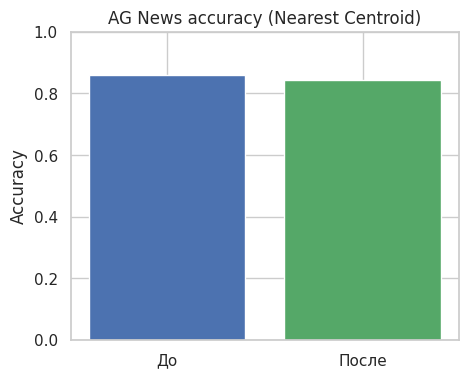

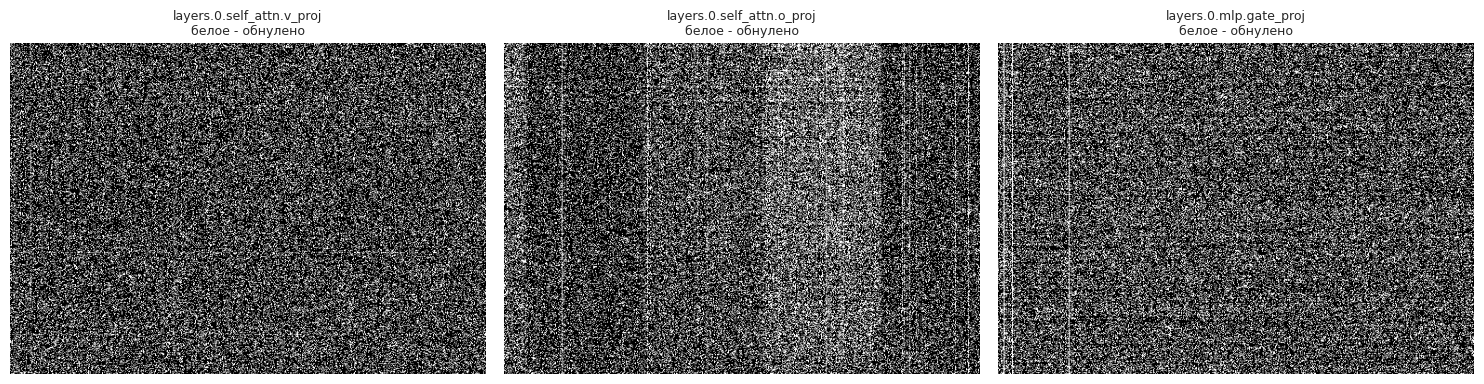

In [21]:
# 1 Сравнение точности
plt.figure(figsize=(5, 4))
plt.bar(["До", "После"], [acc_before, acc_after], color=["#4C72B0", "#55A868"])
plt.ylim(0, 1)
plt.title("AG News accuracy (Nearest Centroid)")
plt.ylabel("Accuracy")
plt.show()

# 2 Визуализация масок для нескольких слоев
n_cols = len(mask_snapshots)
plt.figure(figsize=(5 * n_cols, 4))
for i, (n, mk) in enumerate(mask_snapshots.items(), 1):
    plt.subplot(1, n_cols, i)
    # Покажем случайный фрагмент, если матрица очень большая
    H, W = mk.shape
    max_side = 512
    if H > max_side or W > max_side:
        h0 = np.random.randint(0, max(1, H - max_side + 1))
        w0 = np.random.randint(0, max(1, W - max_side + 1))
        mk_show = mk[h0 : h0 + max_side, w0 : w0 + max_side]
    else:
        mk_show = mk
    plt.imshow(1.0 - mk_show, cmap="gray_r", aspect="auto")
    plt.title(f"{n}\nбелое - обнулено", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Квантизация

Загружаем `Qwen/Qwen3-4B-Instruct-2507` с 4-битным хранением весов линейных слоев в формате NF4 и двойной квантизацией. Вычисления выполняются в BF16, на GPU без аппаратной поддержки BF16 - в FP16. Проверяем загрузку модели, занятую память и генерацию ответа на запрос.

In [22]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

# Освобождаем модели предыдущих блоков перед загрузкой генеративной модели.
del teacher_model, student_model, optimizer, scheduler, scaler
del linears, linears_after, layer_stats, mask_snapshots
del t_emb, s_emb, loss
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()
elif device.type == "mps":
    torch.mps.empty_cache()

In [23]:
if device.type == "cuda":
    print("Устройство:", torch.cuda.get_device_name())
    print(f"Память тензоров до загрузки: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")
elif device.type == "mps":
    print(f"Память тензоров MPS до загрузки: {torch.mps.current_allocated_memory() / 2**30:.2f} GiB")
else:
    print("Устройство: CPU")

Устройство: Tesla T4
Память тензоров до загрузки: 0.02 GiB


In [24]:
model_name = "Qwen/Qwen3-4B-Instruct-2507"

# 4-bit quantization config (bitsandbytes)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",              # 4-битный формат весов
    bnb_4bit_use_double_quant=True,         # двойная квантизация экономит память
    bnb_4bit_compute_dtype=compute_dtype,  # тип вычислений
)

# load the tokenizer and the model (4-bit)
tokenizer = AutoTokenizer.from_pretrained(model_name, revision="cdbee75f17c01a7cc42f958dc650907174af0554")
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map={"": str(device)},
    quantization_config=bnb_config,
    revision="cdbee75f17c01a7cc42f958dc650907174af0554",
)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

In [25]:
%%time
# prepare the model input
prompt = "Дай мне короткую инструкцию о том, как приготовить чизкейк."
messages = [{"role": "user", "content": prompt}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=True,
)
model_inputs = tokenizer([text], return_tensors="pt").to(model.device)

# conduct text completion
generated_ids = model.generate(**model_inputs, max_new_tokens=32768)
output_ids = generated_ids[0][len(model_inputs.input_ids[0]) :].tolist()

# parsing thinking content
try:
    # rindex finding 151668 (</think>)
    index = len(output_ids) - output_ids[::-1].index(151668)
except ValueError:
    index = 0

thinking_content = tokenizer.decode(output_ids[:index], skip_special_tokens=True).strip(
    "\n"
)
content = tokenizer.decode(output_ids[index:], skip_special_tokens=True).strip("\n")

print(content)

Конечно! Вот короткая инструкция по приготовлению классического чизкейка:

---

**Чизкейк — простая инструкция**

**Ингредиенты (на 6–8 порций):**  
- 250 г творога (жёсткого)  
- 100 г сливочного масла (или сливок)  
- 100 г сахара  
- 1 ч. л. соды  
- 2 яйца  
- 1 ч. л. ванили или корицы (по желанию)  
- 100 г шоколада (для покрытия, опционально)

**Шаги:**  
1. В миске смешай творог, сахар, яйца и ваниль.  
2. Добавь сливочное масло (или сливки), соду — всё перемешай.  
3. Влей в форму (или тарелку) и поставь в холодильник на 30 минут.  
4. Покрой поверхность шоколадом (или сахарной пудрой), если хочешь.  
5. Оставь в холодильнике ещё на 1 час — и наслаждайся!

---

*Примечание: Для более нежного вкуса можно использовать творог и сливки, а не масло. Чизкейк получается мягкий и нежный, как пудинг.*

Хорошего аппетита! 🥣🧀
CPU times: user 36.9 s, sys: 75.1 ms, total: 37 s
Wall time: 37.5 s


In [26]:
if device.type == "cuda":
    print(f"Память тензоров после генерации: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")
elif device.type == "mps":
    print(f"Память тензоров MPS после генерации: {torch.mps.current_allocated_memory() / 2**30:.2f} GiB")
print(f"Размер параметров и буферов модели: {model.get_memory_footprint() / 2**30:.2f} GiB")

Память тензоров после генерации: 2.51 GiB
Размер параметров и буферов модели: 2.42 GiB


Модель с 4-битным хранением весов загрузилась и сгенерировала ответ. Счетчик показывает память тензоров на выбранном устройстве. В этом запуске нет полноточной модели для сравнения скорости и качества.

## Источники

- Hinton et al. [Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531).
- Romero et al. [FitNets: Hints for Thin Deep Nets](https://arxiv.org/abs/1412.6550).
- Zhang et al. [Qwen3 Embedding](https://arxiv.org/abs/2506.05176).
- Dettmers et al. [QLoRA](https://arxiv.org/abs/2305.14314).